# Horas pico y valor económico

**Hora pico:** demanda mayor que el percentil 95 del entrenamiento (1.373 MWh). Anticiparlas un día antes sirve para preparar generación de respaldo y reducir el riesgo de cortes. Ojo: por el crecimiento de la demanda, en la prueba ese umbral se supera en 44 % de las horas; en la prueba la tarea equivale a anticipar las horas de demanda alta.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, "../src"); import estilo_tablas; estilo_tablas.activar(); import pipeline_energia as P
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
R = "../resultados/"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
COL = {"Persistencia (misma hora de ayer)": "#9AA5A0", "Estacional (misma hora semana pasada)": "#B8C2BD", "Promedio por hora y día": "#D5DBD8",
       "Ridge (lineal)": "#5B7F96", "Random forest (relativo)": "#1F5A3A", "XGBoost (relativo)": "#C8892B", "Híbrido Ridge + XGBoost (residuo relativo)": "#8E4B7A"}

In [2]:
r = json.load(open(R + "resumen.json")); print("Umbral de hora pico (p95 de entrenamiento): %.0f MWh" % r["umbral_pico_p95_mwh"])
tp = pd.read_csv(R + "prueba.csv"); tp[["modelo", "AUC_pico", "POD", "FAR", "CSI"]].round(3)

Umbral de hora pico (p95 de entrenamiento): 1373 MWh


modelo,AUC_pico,POD,FAR,CSI
Random forest (relativo),"0,974","0,908","0,098","0,827"
XGBoost (relativo),"0,973","0,910","0,100","0,826"
Híbrido Ridge + XGBoost (residuo relativo),"0,971","0,816","0,068","0,770"
Ridge (lineal),"0,966","0,792","0,076","0,743"
Persistencia (misma hora de ayer),"0,926","0,833","0,165","0,716"
Estacional (misma hora semana pasada),"0,906","0,804","0,184","0,681"
Promedio por hora y día,"0,831","0,000","0,000","0,000"


Horas pico en la prueba: 6854 de 15672


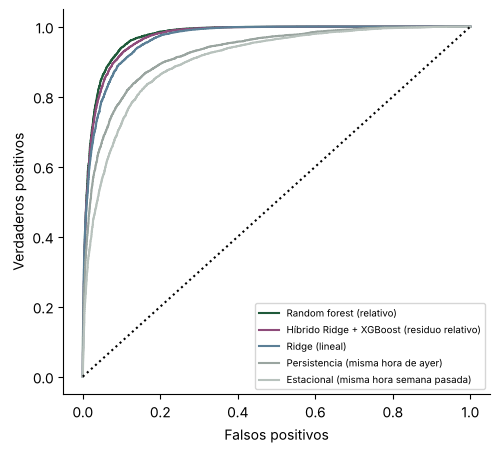

In [3]:
from sklearn.metrics import roc_curve
pt = pd.read_pickle(R + "pred_prueba.pkl"); o = (pt.y > r["umbral_pico_p95_mwh"]).astype(int)
print("Horas pico en la prueba:", int(o.sum()), "de", len(o))
fig, ax = plt.subplots(figsize=(5.5, 5))
for m in ["Random forest (relativo)", "Híbrido Ridge + XGBoost (residuo relativo)", "Ridge (lineal)", "Persistencia (misma hora de ayer)", "Estacional (misma hora semana pasada)"]:
    f, t, _ = roc_curve(o, pt[m]); ax.plot(f, t, label=m, color=COL[m])
ax.plot([0, 1], [0, 1], "k:"); ax.set_xlabel("Falsos positivos"); ax.set_ylabel("Verdaderos positivos"); ax.legend(fontsize=7); plt.show()

## Valor económico: costo de los desvíos
La energía del día siguiente se compra con el pronóstico; cada MWh de diferencia con la demanda real se liquida en la bolsa. Supuesto simplificado: todo desvío, por exceso o por defecto, se paga al **precio de bolsa promedio del día** (XM, métrica PrecBolsNaci). Es una cota superior del valor.

In [4]:
v = pd.read_csv(R + "valor_desvios.csv"); print(json.load(open(R + "valor_supuestos.json"))); v.round(1)

{'dias_prueba': 653, 'precio_bolsa_medio_cop_kwh': 350.02052067381317}


modelo,desvio_MWh_total,desvio_MWh_dia,costo_desvios_COP_millones,costo_anual_COP_millones,ahorro_anual_vs_persistencia_COP_millones
ATER (modelo original),510.672,782,179.596,100.387,81.046
Random forest (relativo),532.526,816,190.106,106.262,75.171
XGBoost (relativo),534.213,818,191.754,107.182,74.250
Híbrido Ridge + XGBoost (residuo relativo),664.934,1.018,248.463,138.880,42.552
Ridge (lineal),728.331,1.115,269.202,150.473,30.960
Persistencia (misma hora de ayer),908.858,1.392,324.590,181.433,0
Estacional (misma hora semana pasada),1.044.273,1.599,354.627,198.222,-16.789
Promedio por hora y día,3.182.677,4.874,1.349.362,754.238,-572.805


## ¿Qué aprende el modelo elegido?
Importancia por permutación del random forest relativo en una muestra de la prueba: cuánto **sube el error (MAE en MWh)** si se desordena cada predictora.

In [5]:
df = pd.read_pickle(R + "datos_horarios.pkl"); X, y = P.construir(df); ok = X.notna().all(axis=1); X, y = X[ok], y[ok]
tr = X.index < pd.Timestamp("2025-01-01") - pd.Timedelta(hours=48); te = X.index >= pd.Timestamp("2025-01-01")
m = P.GRILLAS_V2["Random forest (relativo)"]["hoja5"]().fit(X[tr], y[tr])
Xs = X[te].sample(4000, random_state=2026); ys = y[Xs.index]
base = np.mean(np.abs(ys.values - m.predict(Xs))); rng = np.random.default_rng(2026); filas = []
for c in Xs.columns:
    d = []
    for _ in range(5):
        Xp = Xs.copy(); Xp[c] = rng.permutation(Xp[c].values); d.append(np.mean(np.abs(ys.values - m.predict(Xp))) - base)
    filas.append((c, np.mean(d), np.std(d)))
print("MAE base de la muestra: %.1f MWh" % base)
imp = pd.DataFrame(filas, columns=["variable", "aumento_MAE_MWh", "sd"]).sort_values("aumento_MAE_MWh", ascending=False)
imp.to_csv(R + "importancia_rf_relativo.csv", index=False); imp.head(15).round(2)

MAE base de la muestra: 34.3 MWh


variable,aumento_MAE_MWh,sd
media_7d,"16,95","0,570"
max_dia_ant,"16,37","0,200"
media_misma_hora_4sem,"15,73","0,320"
lag24,"15,44","0,280"
hora_sin,"13,28","0,210"
calor_x_hora,"7,27","0,240"
tipo_dia,"6,23","0,300"
dow,"2,84","0,150"
media_dia_ant,"2,32","0,130"
hora,"2,01","0,090"


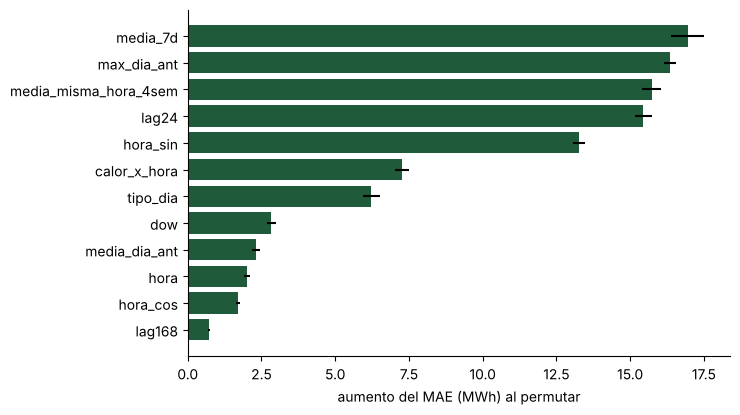

In [6]:
top = imp.head(12).iloc[::-1]; fig, ax = plt.subplots(figsize=(7, 4.5)); ax.barh(top.variable, top.aumento_MAE_MWh, xerr=top.sd, color="#1F5A3A")
ax.set_xlabel("aumento del MAE (MWh) al permutar"); plt.show()

 **Resultado.**

- **Picos:** el random forest relativo anticipa con un día el **91 %** de las horas pico extremas con **10 %** de falsas alarmas (AUC 0,974; CSI 0,83). La persistencia detecta el 83 % pero con 17 % de falsas alarmas (CSI 0,72), y el promedio por hora y día no detecta ninguna.
- **Plata:** con el precio de bolsa real de 2025–2026 (en promedio \\$350/kWh), el modelo elegido reduce el desvío de 1.392 a 816 MWh por día y el costo de los desvíos en unos **\\$75.000 millones al año** frente a la persistencia. Es una cota superior por el supuesto de liquidación, pero muestra el orden de magnitud.
- **Qué aprende:** lo que más pesa es el **nivel y la historia reciente** (media de los 7 días anteriores, máximo de ayer, misma hora de las últimas 4 semanas, misma hora de ayer: 15–17 MWh de aumento del MAE cada una), luego la **hora** (13,3) y la **interacción calor × hora** (7,3): el calor de Sabanagrande pesa sobre todo en ciertas horas del día. Le siguen el tipo de día (6,2) y el día de la semana (2,8).